In [19]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv("../data/simulation_language_results.csv")
df.head()

,sim,model_knowledge,w,perf,perf_stake,baseline_reward,avg_reward
0,0,0.0,0.00,0.085938,0.210938,5.027344,5.113281
1,0,0.0,0.01,0.156250,0.156250,5.027344,5.183594
2,0,0.0,0.02,0.011719,-0.285156,5.027344,5.039062
3,0,0.0,0.03,0.105469,0.074219,5.027344,5.132812
4,0,0.0,0.04,0.097656,-0.011719,5.027344,5.125000


In [21]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf_stake"].mean()
)
df_plot

,model_knowledge,w,perf_stake
0,0.0,0.00,0.500430
1,0.0,0.01,0.483203
2,0.0,0.02,0.426992
3,0.0,0.03,0.370039
4,0.0,0.04,0.440312
...,...,...,...
10196,1.0,0.96,1.500391
10197,1.0,0.97,1.561875
10198,1.0,0.98,1.536289
10199,1.0,0.99,1.544844


In [22]:
df_plot = (
    df.groupby(["model_knowledge", "w"], as_index=False)["perf_stake"]
      .mean()
      .assign(
          model_knowledge=lambda d: d["model_knowledge"].round(2),
          w=lambda d: d["w"].round(2)
      )
)
df_plot.head()

,model_knowledge,w,perf_stake
0,0.0,0.00,0.500430
1,0.0,0.01,0.483203
2,0.0,0.02,0.426992
3,0.0,0.03,0.370039
4,0.0,0.04,0.440312


In [23]:
matrix = df_plot.pivot(index="model_knowledge", columns="w", values="perf_stake")
matrix.head()

w,0.00,0.01,0.02,0.03,0.04,0.05,0.06,0.07,0.08,0.09,...,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,1.00
model_knowledge,,,,,,,,,,,,,,,,,,,,,
0.00,0.500430,0.483203,0.426992,0.370039,0.440312,0.402227,0.384805,0.366836,0.217461,0.303594,...,-1.570078,-1.520625,-1.501953,-1.558555,-1.455391,-1.580078,-1.498359,-1.485898,-1.366992,-1.486797
0.01,0.529414,0.477930,0.483281,0.452422,0.443164,0.338086,0.350820,0.377695,0.373164,0.320000,...,-1.458828,-1.492188,-1.457812,-1.492227,-1.491289,-1.526211,-1.511992,-1.479258,-1.457148,-1.333477
0.02,0.493359,0.523633,0.495898,0.421094,0.428945,0.382695,0.368945,0.276562,0.340508,0.337227,...,-1.502773,-1.435312,-1.558555,-1.473828,-1.455391,-1.452461,-1.535664,-1.449336,-1.444727,-1.460312
0.03,0.557422,0.518672,0.431797,0.432422,0.362109,0.393242,0.412930,0.321836,0.283867,0.305117,...,-1.495234,-1.453477,-1.422773,-1.475000,-1.417930,-1.527539,-1.441875,-1.497305,-1.454063,-1.458086
0.04,0.466250,0.469102,0.455352,0.457227,0.346094,0.392383,0.372695,0.356797,0.359453,0.283398,...,-1.446953,-1.533906,-1.468398,-1.516641,-1.565508,-1.502344,-1.530742,-1.430937,-1.456250,-1.451211


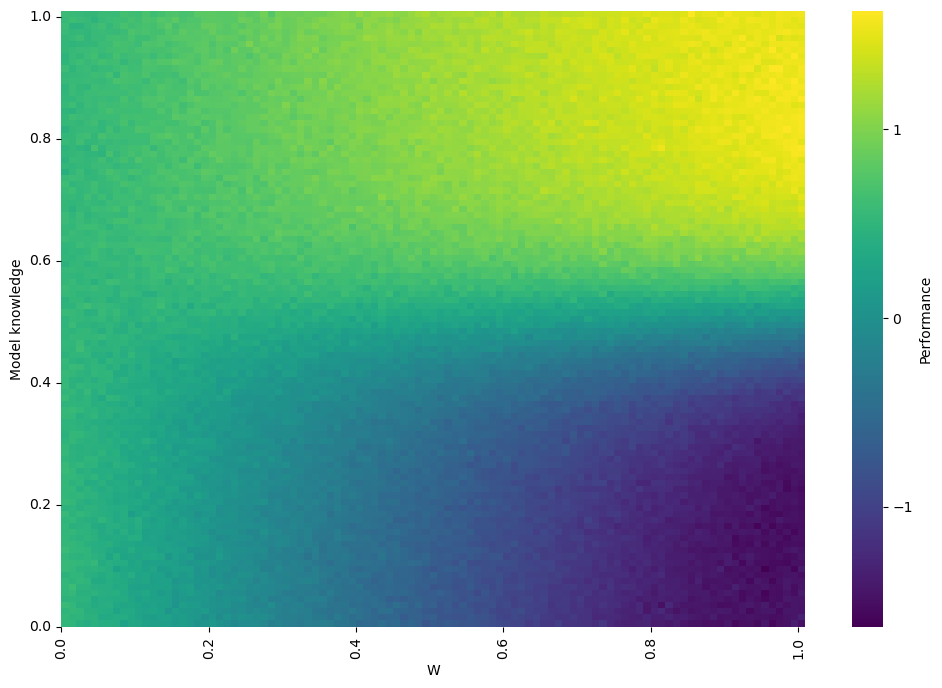

In [24]:
plt.figure(figsize=(12, 8))

sns.heatmap(matrix, cmap="viridis", annot=False, cbar_kws={"label": "Performance", "ticks": [-1., 0.0, 1.]})

# plt.contour(matrix.values, levels=[0], colors="black", linewidths=1)
# plt.axhline(y=50, color="red", linestyle="--", linewidth=2)

plt.gca().invert_yaxis()
plt.ylabel("Model knowledge")
plt.xlabel("W")

# Use the actual index and columns
plt.yticks(
    np.arange(0, len(matrix.index), 20),   # positions
    matrix.index[::20]                     # labels
)
plt.xticks(
    np.arange(0, len(matrix.columns), 20),  # positions
    matrix.columns[::20]                    # labels
)

plt.show()


## Mapping real data on the matrix

get value from behaviour data

In [25]:
df_behaviour = pd.read_csv("../data/data_participants.csv")
df_w_language = pd.read_csv("../data/data_participants_w_language.csv")
df_w_observation = pd.read_csv("../data/data_participants_w_observation.csv")

df_behaviour["gen"] = df_behaviour["gen"] + 1
df_behaviour["pl2_understanding"] = (df_behaviour["pl2_understanding"] * 50 + 50) / 100

df_language = df_behaviour.query('cond == "ADV"')
language_value = {
    "gen": range(1, 11),
    "perf": df_language.groupby("gen")["score_corrected"].mean().round(2),
    "model_knowledge": df_language.groupby("gen")["pl2_understanding"].mean().round(2),
    "w": df_w_language.groupby("generation")["w"].mean().round(2)
}
df_language = pd.DataFrame(language_value)

df_observation = df_behaviour.query('cond == "OBS"')
observation_value = {
    "gen": range(1, 11),
    "perf": df_observation.groupby("gen")["score_corrected"].mean().round(2),
    "model_knowledge": df_observation.groupby("gen")["pl2_understanding"].mean().round(2),
    "w": df_w_observation.groupby("generation")["w"].mean().round(2)
}
df_observation = pd.DataFrame(observation_value)

value from the sim

In [26]:
df_sim = pd.read_csv("../data/simulation_language_results.csv")
df_sim = (
    df_sim.groupby(["model_knowledge", "w"], as_index=False)["perf_stake"].mean().round(2)
)
df_sim = df_sim.rename(columns={"perf_stake": "perf_sim"})
df_sim

,model_knowledge,w,perf_sim
0,0.0,0.00,0.50
1,0.0,0.01,0.48
2,0.0,0.02,0.43
3,0.0,0.03,0.37
4,0.0,0.04,0.44
...,...,...,...
10196,1.0,0.96,1.50
10197,1.0,0.97,1.56
10198,1.0,0.98,1.54
10199,1.0,0.99,1.54


In [27]:
df_language = df_language.merge(
    df_sim[["model_knowledge", "w", "perf_sim"]],
    on=["model_knowledge", "w"],
    how="left"
)
df_language

,gen,perf,model_knowledge,w,perf_sim
0,1,0.19,0.53,0.51,0.46
1,2,0.25,0.52,0.53,0.38
2,3,0.31,0.53,0.51,0.46
3,4,0.43,0.52,0.51,0.40
4,5,0.45,0.55,0.52,0.46
5,6,0.43,0.57,0.53,0.67
6,7,0.45,0.60,0.53,0.77
7,8,0.70,0.65,0.60,0.96
8,9,1.15,0.74,0.66,1.15
9,10,1.06,0.75,0.69,1.23


In [28]:
df_observation = df_observation.merge(
    df_sim[["model_knowledge", "w", "perf_sim"]],
    on=["model_knowledge", "w"],
    how="left"
)
df_observation

,gen,perf,model_knowledge,w,perf_sim
0,1,0.30,0.51,0.49,0.36
1,2,0.20,0.52,0.49,0.40
2,3,0.28,0.51,0.49,0.36
3,4,0.33,0.53,0.51,0.46
4,5,0.05,0.51,0.49,0.36
5,6,0.18,0.52,0.51,0.40
6,7,0.31,0.52,0.49,0.40
7,8,0.21,0.52,0.51,0.40
8,9,0.30,0.53,0.53,0.49
9,10,0.26,0.52,0.49,0.40


merger & save data for R

In [29]:
df_language["condition"] = "language"
df_observation["condition"] = "observation"
df = pd.concat([df_language, df_observation], ignore_index=True)
df.to_csv("../data/data_matrix_behaviour_comparaison.csv", index=False)

## plot

In [30]:
df

,gen,perf,model_knowledge,w,perf_sim,condition
0,1,0.19,0.53,0.51,0.46,language
1,2,0.25,0.52,0.53,0.38,language
2,3,0.31,0.53,0.51,0.46,language
3,4,0.43,0.52,0.51,0.40,language
4,5,0.45,0.55,0.52,0.46,language
5,6,0.43,0.57,0.53,0.67,language
6,7,0.45,0.60,0.53,0.77,language
7,8,0.70,0.65,0.60,0.96,language
8,9,1.15,0.74,0.66,1.15,language
9,10,1.06,0.75,0.69,1.23,language


Performance

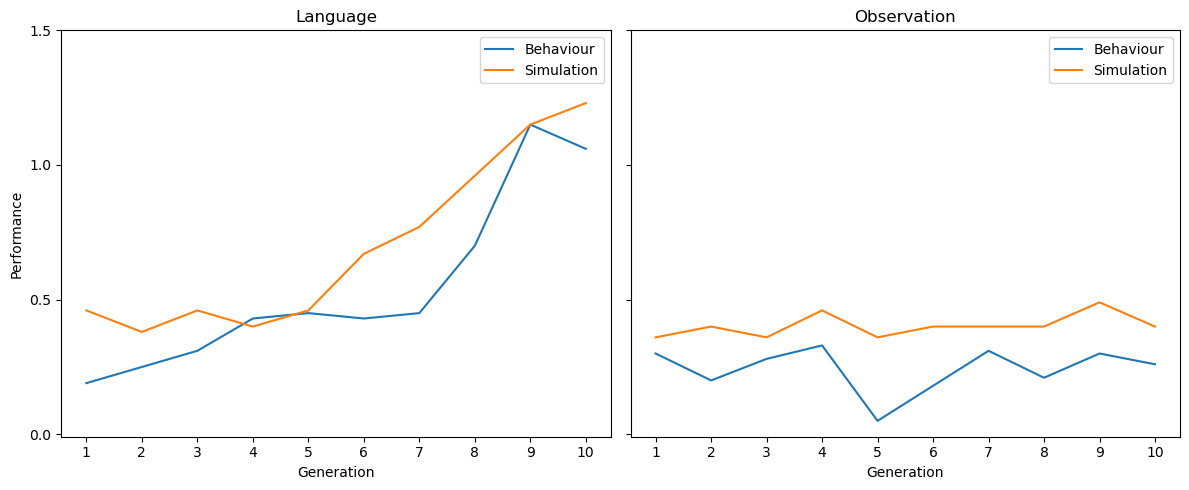

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

# Language
ax = axes[0]
df_plot_language = df.query('condition == "language"')

ax.plot("gen", "perf", data=df_plot_language, label="Behaviour")
ax.plot("gen", "perf_sim", data=df_plot_language, label="Simulation")

ax.set_title("Language")
ax.set_xlabel("Generation")
ax.set_ylabel("Performance")

ax.set_xticks(range(1, 11, 1))
ax.set_yticks([0, 0.5, 1.0, 1.5])
ax.legend()

# Observation
ax = axes[1]
df_plot_observation = df.query('condition == "observation"')

ax.plot("gen", "perf", data=df_plot_observation, label="Behaviour")
ax.plot("gen", "perf_sim", data=df_plot_observation, label="Simulation")

ax.set_title("Observation")
ax.set_xlabel("Generation")

ax.set_xticks(range(1, 11, 1))
ax.set_yticks([0, 0.5, 1.0, 1.5])
ax.legend()

plt.tight_layout()
plt.show()